# Live Snapshot Exploration

Explores a single call to the [Amtraker API](https://api-v3.amtraker.com/v3/trains): what the raw JSON looks like, how it is flattened into train-level and station-level tables, and how trains are performing right now. The data is cached in `data/raw/raw.json` for 30 minutes, so re-running this notebook shows the current state of the network.

Note: the API also includes VIA Rail Canada trains (train numbers starting with `v`).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from automated_collection import HistoricalDataManager

manager = HistoricalDataManager()
raw_data = manager.collector.get_train_data()

print(f"Number of train groups: {len(raw_data)}")
first_train = next(iter(raw_data.values()))[0]
print(f"Keys in a train: {list(first_train.keys())}")
print(f"Keys in a station: {list(first_train['stations'][0].keys())}")

Calling API for fresh data


Success!
Number of train groups: 180
Keys in a train: ['dataSource', 'routeName', 'trainNum', 'trainNumRaw', 'trainID', 'lat', 'lon', 'trainTimely', 'iconColor', 'textColor', 'stations', 'heading', 'eventCode', 'eventTZ', 'eventName', 'origCode', 'originTZ', 'origName', 'destCode', 'destTZ', 'destName', 'trainState', 'velocity', 'statusMsg', 'createdAt', 'updatedAt', 'lastValTS', 'provider', 'providerShort', 'onlyOfTrainNum', 'alerts']
Keys in a station: ['name', 'code', 'tz', 'bus', 'schArr', 'schDep', 'arr', 'dep', 'arrCmnt', 'depCmnt', 'status', 'stopIconColor', 'platform']


## Train-level table

One row per active train: position, speed, heading, origin and destination.

In [2]:
trains_df = manager.process_train_data(raw_data)
print(f"Shape: {trains_df.shape}")
trains_df.head()

Shape: (193, 13)


,train_number,route_name,train_id,lat,lon,heading,velocity,train_state,status_msg,origin_code,dest_code,num_stations,collection_timestamp
0,1,Sunset Limited,1-11,29.693498,-91.197119,W,24.680857,Active,,NOL,LAX,22,2026-11-11 12:05:29
1,3,Southwest Chief,3-10,36.196085,-104.660769,S,70.202499,Active,,CHI,LAX,32,2026-11-11 12:05:29
2,4,Southwest Chief,4-9,40.544544,-91.529105,E,50.616882,Active,,LAX,CHI,32,2026-11-11 12:05:29
3,4,Southwest Chief,4-10,35.508589,-108.437091,E,78.727707,Active,,LAX,CHI,32,2026-11-11 12:05:29
4,5,California Zephyr,5-9,39.514497,-119.631643,W,32.149738,Active,,CHI,EMY,35,2026-11-11 12:05:29


## Station-level table

One row per stop on each train's route. API times include UTC offsets, so they are converted to UTC before computing delays.

In [3]:
stations_df = manager.process_station_data(raw_data)
print(f"Shape: {stations_df.shape}")
print(stations_df['status'].value_counts().to_string())
stations_df.head()

Shape: (3415, 14)
status
Enroute     1850
Departed    1507
Station       58


,train_number,train_id,route_name,station_name,station_code,scheduled_arrival,actual_arrival,scheduled_departure,actual_departure,status,timezone,departure_delay_minutes,arrival_delay_minutes,collection_timestamp
0,1,1-11,Sunset Limited,New Orleans,NOL,2026-11-11 15:00:00+00:00,2026-11-11 15:00:00+00:00,2026-11-11 15:00:00+00:00,2026-11-11 15:00:00+00:00,Departed,America/Chicago,0.0,0.0,2026-11-11 12:05:29
1,1,1-11,Sunset Limited,Schriever,SCH,2026-11-11 16:30:00+00:00,2026-11-11 16:25:00+00:00,2026-11-11 16:30:00+00:00,2026-11-11 16:30:00+00:00,Departed,America/Chicago,0.0,-5.0,2026-11-11 12:05:29
2,1,1-11,Sunset Limited,New Iberia,NIB,2026-11-11 17:56:00+00:00,2026-11-11 18:01:00+00:00,2026-11-11 17:56:00+00:00,2026-11-11 18:01:00+00:00,Enroute,America/Chicago,5.0,5.0,2026-11-11 12:05:29
3,1,1-11,Sunset Limited,Lafayette,LFT,2026-11-11 18:24:00+00:00,2026-11-11 18:24:00+00:00,2026-11-11 18:24:00+00:00,2026-11-11 18:24:00+00:00,Enroute,America/Chicago,0.0,0.0,2026-11-11 12:05:29
4,1,1-11,Sunset Limited,Lake Charles,LCH,2026-11-11 19:55:00+00:00,2026-11-11 19:55:00+00:00,2026-11-11 19:55:00+00:00,2026-11-11 19:55:00+00:00,Enroute,America/Chicago,0.0,0.0,2026-11-11 12:05:29


## How trains are doing right now

Only stops trains have already departed, so these are actual delays.

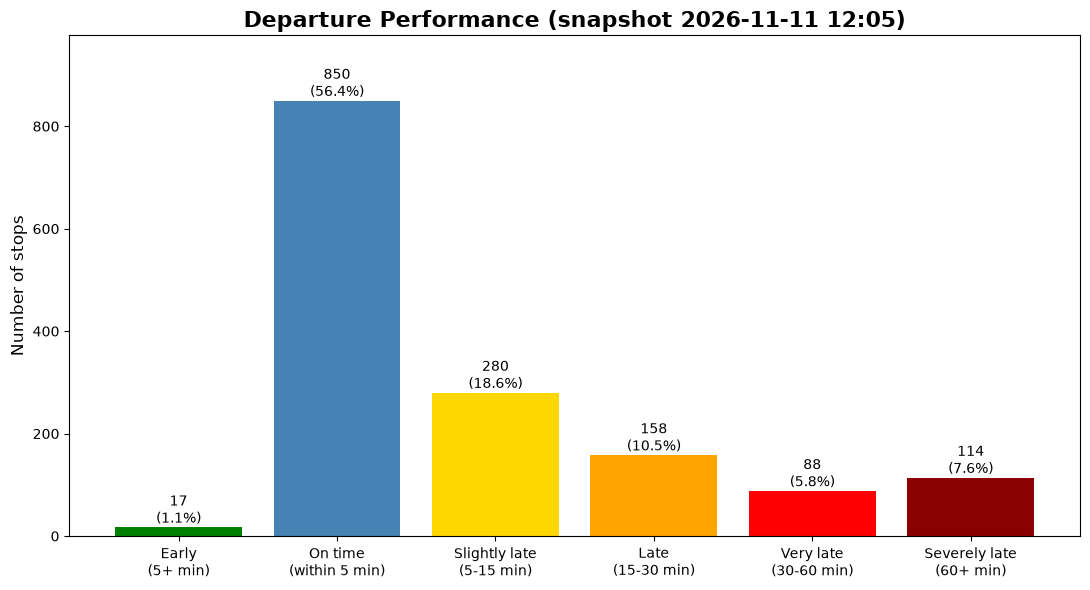

Departed stops in snapshot: 1507


In [4]:
DELAY_BINS = [-60, -5, 5, 15, 30, 60, float('inf')]
DELAY_LABELS = ['Early\n(5+ min)', 'On time\n(within 5 min)', 'Slightly late\n(5-15 min)',
                'Late\n(15-30 min)', 'Very late\n(30-60 min)', 'Severely late\n(60+ min)']
DELAY_COLORS = ['green', 'steelblue', 'gold', 'orange', 'red', 'darkred']


def plot_departure_performance(delays, title, save_path=None):
  categories = pd.cut(delays, bins=DELAY_BINS, labels=DELAY_LABELS)
  counts = categories.value_counts().reindex(DELAY_LABELS, fill_value=0)
  percents = counts / counts.sum() * 100

  fig, ax = plt.subplots(figsize=(11, 6))
  bars = ax.bar(counts.index, counts.values, color=DELAY_COLORS)
  ax.bar_label(bars, labels=[f'{c}\n({p:.1f}%)' for c, p in zip(counts, percents)])
  ax.set_title(title, fontsize=16, fontweight='bold')
  ax.set_ylabel('Number of stops', fontsize=12)
  ax.margins(y=0.15)
  fig.tight_layout()
  if save_path:
    fig.savefig(save_path, dpi=150, bbox_inches='tight')
  plt.show()
  return percents


departed = stations_df[stations_df['status'] == 'Departed']
snapshot_time = stations_df['collection_timestamp'].iloc[0]
plot_departure_performance(departed['departure_delay_minutes'], f'Departure Performance (snapshot {snapshot_time:%Y-%m-%d %H:%M})')
print(f"Departed stops in snapshot: {len(departed)}")

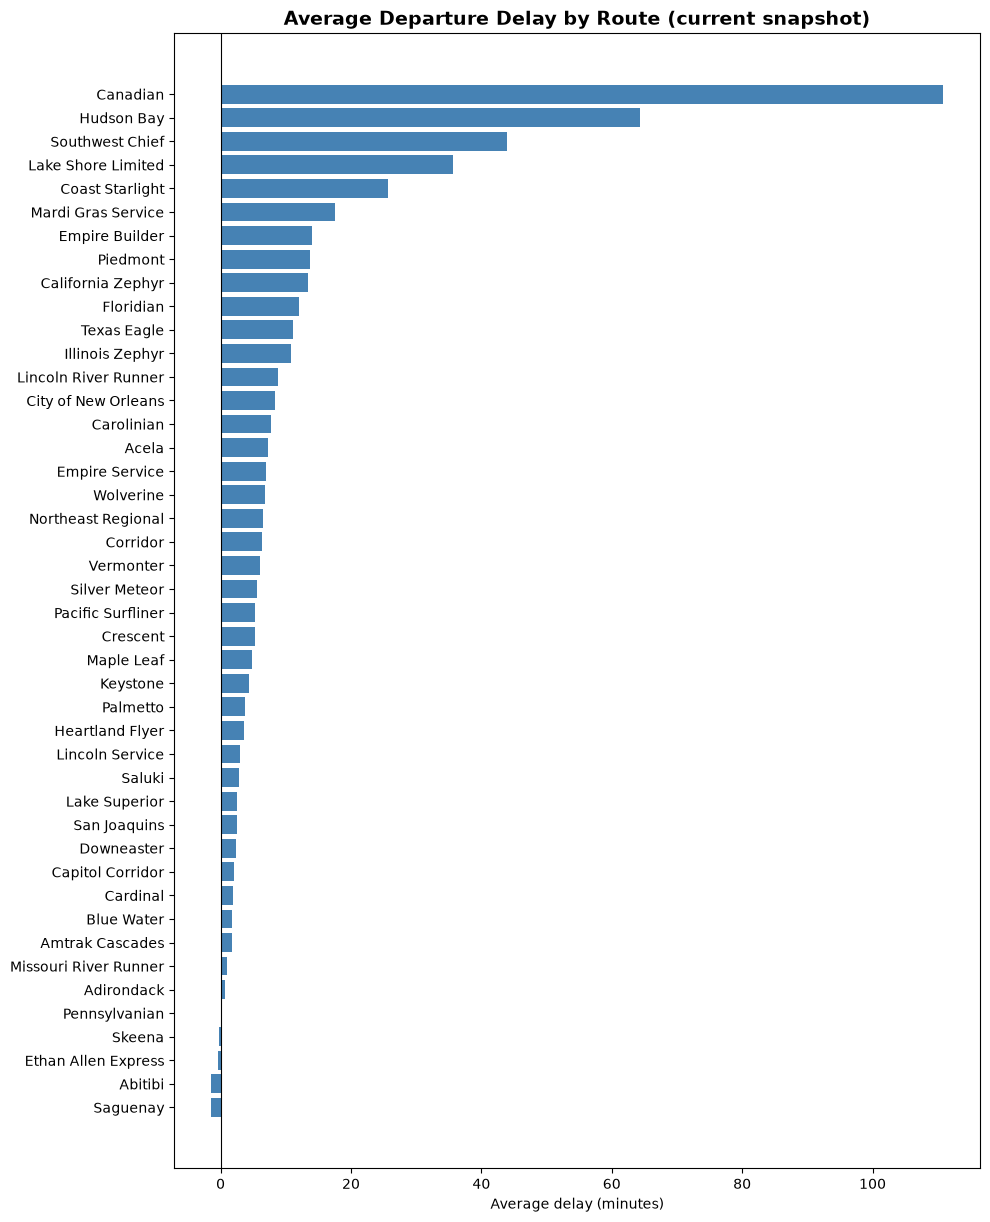

In [5]:
route_delays = (departed.groupby('route_name')['departure_delay_minutes']
                 .agg(['mean', 'count'])
                 .query('count >= 5')
                 .sort_values('mean'))

fig, ax = plt.subplots(figsize=(10, max(5, len(route_delays) * 0.28)))
ax.barh(route_delays.index, route_delays['mean'], color='steelblue')
ax.axvline(0, color='black', linewidth=0.8)
ax.set_title('Average Departure Delay by Route (current snapshot)', fontsize=14, fontweight='bold')
ax.set_xlabel('Average delay (minutes)')
fig.tight_layout()
plt.show()